# STEP 5 · 미추홀구 I-MOD 후보 권역 도출 및 검증
**대상: 2026년 4~6월 관측 286개 정류장군.** STEP 4의 점수는 '탐색 우선순위'이며 공급 부족 증거가 아닙니다.

**입력 파일 2개**: `02_all_286_with_scores.csv` (STEP 4), `04_StopGroup_Hourly_2026Q2.csv` (기존 시간대별 통합본). 37개 위치 미확정 정류장명은 점수에는 남기고 지도·권역 분석에서는 제외합니다. 경계 거리 임계값은 탐색적 시나리오이며 실제 도로 접근성/OD를 반영하지 않습니다.

In [3]:
import os, io, glob, warnings, zipfile, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from IPython.display import display
from google.colab import files
OUT=Path('IMOD_STEP5_Results'); OUT.mkdir(exist_ok=True)
print('두 CSV를 선택하세요: 02_all_286_with_scores.csv + 04_StopGroup_Hourly_2026Q2.csv')
uploaded=files.upload()
def load(marker):
    matches=[k for k in uploaded if marker in k]
    if len(matches)!=1: raise ValueError(f'{marker} 파일이 {len(matches)}개 인식됐습니다. 업로드 목록: {list(uploaded)}')
    return pd.read_csv(io.BytesIO(uploaded[matches[0]]),encoding='utf-8-sig')
scores=load('all_286_with_scores'); hourly=load('StopGroup_Hourly')
print('scores',scores.shape,'hourly',hourly.shape)
assert len(scores)==286 and scores.station_name.nunique()==286
assert len(hourly)==617760 and hourly.station_name.nunique()==286


두 CSV를 선택하세요: 02_all_286_with_scores.csv + 04_StopGroup_Hourly_2026Q2.csv


Saving 04_StopGroup_Hourly_2026Q2.csv to 04_StopGroup_Hourly_2026Q2 (2).csv
Saving 05_all_286_with_scores.csv to 05_all_286_with_scores.csv
scores (286, 50) hourly (617760, 25)


## 1. 공간 매칭, 가중치 시나리오 및 상위권 반복 선정
**핵심 원칙:** 점수 가중치가 달라도 반복적으로 나타나는 후보를 표시하되, STEP 4 점수의 순위가 곧 공급 부족 정도는 아님. 상위 20위는 가중치별 수요 적격성(`eligible_median=True`)을 공통으로 유지한 후 비교.

In [4]:
required=['station_name','avg_daily_passengers','avg_daily_operations','score_base', 'rank_base','rank_demand_priority','rank_time_priority','rank_balanced','representative_latitude','representative_longitude','spatial_confidence','eligible_median']
missing=[c for c in required if c not in scores.columns]
if missing:raise ValueError(f'입력 컬럼 누락: {missing}')
for c in ['avg_daily_passengers','avg_daily_operations','score_base','rank_base','rank_demand_priority','rank_time_priority','rank_balanced','representative_latitude','representative_longitude']:
    scores[c]=pd.to_numeric(scores[c],errors='coerce')
scores['eligible_median']=scores['eligible_median'].astype(str).str.lower().eq('true')
scores['spatial_valid']=(scores.spatial_confidence.isin(['high','medium']) & scores.representative_latitude.between(37,38)&scores.representative_longitude.between(126,127))
rank_cols=['rank_base','rank_demand_priority','rank_time_priority','rank_balanced']
# 전체 286명 중 각 순위가 상위 20인 후보(수요 적격군만)
for c in rank_cols:
    scores[c+'_top20'] = scores.eligible_median & scores[c].le(20)
scores['top20_frequency']=scores[[c+'_top20' for c in rank_cols]].sum(axis=1)
scores['candidate_tier']=np.select([scores.top20_frequency>=3,scores.top20_frequency==2,scores.top20_frequency==1],['high_repeat','medium_repeat','single_scenario'],default='not_top20')
print('공간 상태:');display(scores.groupby(['spatial_confidence','spatial_valid']).size().rename('n').reset_index())
print('반복 선정:');display(scores.candidate_tier.value_counts().to_frame('n'))
print('수요 적격+기본 상위 20 중 공간 미확정:');display(scores.loc[scores.rank_base.le(20)&~scores.spatial_valid,['station_name','rank_base','spatial_group_status']])
scores.to_csv(OUT/'01_all_286_candidate_flags.csv',index=False,encoding='utf-8-sig')


공간 상태:


,spatial_confidence,spatial_valid,n
0,high,True,136
1,medium,True,113
2,unresolved,False,37


반복 선정:


,n
candidate_tier,
not_top20,261
single_scenario,11
high_repeat,7
medium_repeat,7


수요 적격+기본 상위 20 중 공간 미확정:


,station_name,rank_base,spatial_group_status
18,관교여자중학교,20,spatially_split_ambiguous
205,인하대후문,3,spatially_split_ambiguous


## 2. 권역 탐색: 300m·500m·800m, 후보 풀 20·40·60
반경은 구면 거리(haversine)를 사용한 **DBSCAN eps**이며, **연결된 중간 지점이 있으면 양 끝 거리는 eps보다 멀 수 있습니다**. 구성 정류장군 수 2개 이상을 권역 후보로 표기하고 1개는 `singleton`으로 표시합니다. 500m/상위40은 탐색용 기준 사례이지 최종 확정 기준이 아닙니다.

In [5]:
def group_candidates(pool=40,radius_m=500,min_demand=True):
    eligible=scores[scores.spatial_valid & (scores.eligible_median if min_demand else True)].copy()
    eligible=eligible.sort_values(['rank_base','station_name']).head(pool).copy()
    if eligible.empty:return eligible
    coords=np.radians(eligible[['representative_latitude','representative_longitude']].to_numpy())
    labels=DBSCAN(eps=radius_m/6371008.8,min_samples=1,metric='haversine').fit_predict(coords)
    eligible['component']=labels
    eligible['zone_id']=[f'R{radius_m}_N{pool}_C{i:02d}' for i in labels]
    sz=eligible.groupby('zone_id').zone_id.transform('size')
    eligible['zone_type']=np.where(sz>=2,'multi_stop_zone','singleton')
    eligible['radius_m']=radius_m;eligible['pool']=pool
    return eligible
runs=[];summary=[]
for pool in [20,40,60]:
 for radius in [300,500,800]:
    d=group_candidates(pool,radius);runs.append(d)
    zs=d.groupby('zone_id').agg(n=('station_name','size'),n_repeat=('top20_frequency',lambda x:(x>=2).sum())).reset_index()
    summary.append(dict(pool=pool,radius_m=radius,n_geocoded_candidates=len(d),n_multistop_zones=(zs.n>=2).sum(),n_singletons=(zs.n==1).sum(),n_members_multistop=zs.loc[zs.n>=2,'n'].sum(),largest_zone=zs.n.max()))
scenario_summary=pd.DataFrame(summary)
display(scenario_summary)
scenario_summary.to_csv(OUT/'02_spatial_scenario_summary.csv',index=False,encoding='utf-8-sig')
all_scenarios=pd.concat(runs,ignore_index=True)
all_scenarios[['station_name','stop_group_id','pool','radius_m','zone_id','zone_type','top20_frequency','rank_base']].to_csv(OUT/'03_all_spatial_scenario_memberships.csv',index=False,encoding='utf-8-sig')
BASE_POOL=40;BASE_RADIUS=500
base=group_candidates(BASE_POOL,BASE_RADIUS)
base.to_csv(OUT/'04_base_zone_memberships.csv',index=False,encoding='utf-8-sig')


,pool,radius_m,n_geocoded_candidates,n_multistop_zones,n_singletons,n_members_multistop,largest_zone
0,20,300,20,2,16,4,2
1,20,500,20,2,14,6,4
2,20,800,20,4,5,15,7
3,40,300,40,5,29,11,3
4,40,500,40,8,14,26,7
5,40,800,40,4,2,38,28
6,60,300,60,8,40,20,4
7,60,500,60,13,7,53,9
8,60,800,60,3,1,59,44


## 3. 권역 프로파일: 수요·공급 규모와 유형
`합계`는 선정된 **서로 다른 정류장명**의 일평균 집계값을 한 번씩 더한 값입니다. 중복된 실제 사람/노선까지 제거한 고유 이용객이 아니며, 미충족수요나 수용능력을 나타내지 않습니다.

In [6]:
zones=(base.groupby('zone_id').agg(
  n_stop_groups=('station_name','size'),
  station_names=('station_name',lambda v:' | '.join(v)),
  avg_daily_boardings_sum=('avg_daily_passengers','sum'),
  avg_daily_operations_sum=('avg_daily_operations','sum'),
  mismatch_median=('temporal_mismatch','median'),
  avg_base_score=('score_base','mean'),
  repeat_2plus=('top20_frequency',lambda x:(x>=2).sum()),
  latitude=('representative_latitude','mean'),longitude=('representative_longitude','mean'),
  high_confidence_n=('spatial_confidence',lambda v:(v=='high').sum()),
  medium_confidence_n=('spatial_confidence',lambda v:(v=='medium').sum())
).reset_index())
zones['zone_type']=np.where(zones.n_stop_groups>=2,'multi_stop_zone','singleton')
zones=zones.sort_values(['repeat_2plus','avg_base_score'],ascending=False)
display(zones.head(20))
zones.to_csv(OUT/'05_base_zone_profiles.csv',index=False,encoding='utf-8-sig')


,zone_id,n_stop_groups,station_names,avg_daily_boardings_sum,avg_daily_operations_sum,mismatch_median,avg_base_score,repeat_2plus,latitude,longitude,high_confidence_n,medium_confidence_n,zone_type
7,R500_N40_C07,5,주안7동행정복지센터 | 신기.남부종합시장(진흥사거리) | 주안남초등학교 | 힐스테이...,6178.922222,3770.355555,0.171480,61.251748,2,37.450296,126.679591,2,3,multi_stop_zone
1,R500_N40_C01,1,롯데백화점(인천터미널),10306.455556,2553.288889,0.230978,72.132867,1,37.443106,126.701493,1,0,singleton
2,R500_N40_C02,1,문학경기장(야구장),309.477778,456.133333,0.411426,69.318182,1,37.438335,126.691498,1,0,singleton
4,R500_N40_C04,1,문학초등학교,925.788889,554.244444,0.186875,67.290210,1,37.438578,126.682378,0,1,singleton
5,R500_N40_C05,1,용현3동행정복지센터.보훈병원,1206.344444,716.677778,0.180046,67.220280,1,37.456443,126.651578,0,1,singleton
0,R500_N40_C00,2,남중학교 | 인화여고,1042.666667,1628.300000,0.237839,66.608392,1,37.466884,126.654319,0,2,multi_stop_zone
6,R500_N40_C06,2,한양아파트 | 토지금고시장,869.466667,528.877778,0.203655,63.321678,1,37.451179,126.638156,1,1,multi_stop_zone
3,R500_N40_C03,4,주안역 | 주안역환승정류장 | 공단시장 | 태화아파트,12484.322222,3236.911111,0.212191,61.520979,1,37.465765,126.679059,0,4,multi_stop_zone
9,R500_N40_C09,1,인천소방본부,735.011111,911.733333,0.208052,64.265734,0,37.448718,126.669862,0,1,singleton
11,R500_N40_C11,1,인천고등학교,548.366667,717.488889,0.215537,63.041958,0,37.452433,126.689773,0,1,singleton


## 4. 월별 프로파일 검증
일평균 수요/운행은 월별 정상 관측일로 나누어 계산합니다. 6월 11일은 의도적으로 제외하므로 **4월 30일, 5월 31일, 6월 29일**을 기대합니다. 월별 절대 수치가 아닌 날짜당 평균을 비교합니다.

In [7]:
hourly['date']=pd.to_datetime(hourly.date.astype(str),format='%Y%m%d',errors='coerce')
hourly['month']=hourly.date.dt.strftime('%Y-%m')
for c in ['passenger_count','operation_count','hour']:
 hourly[c]=pd.to_numeric(hourly[c],errors='coerce')
month_days=hourly.groupby('month').date.nunique()
print('월별 관측일:',month_days.to_dict())
assert month_days.to_dict()=={'2026-04':30,'2026-05':31,'2026-06':29}, '관측일 수 확인 필요'
name_zone=base[['station_name','zone_id']].copy()
month_data=hourly.merge(name_zone,on='station_name',how='inner',validate='many_to_one')
monthly=month_data.groupby(['zone_id','month']).agg(boardings=('passenger_count','sum'),operations=('operation_count','sum')).reset_index()
monthly['observed_days']=monthly.month.map(month_days)
monthly['avg_daily_boardings']=monthly.boardings/monthly.observed_days
monthly['avg_daily_operations']=monthly.operations/monthly.observed_days
monthly.to_csv(OUT/'06_monthly_zone_profiles.csv',index=False,encoding='utf-8-sig')
monthly_cv=monthly.groupby('zone_id').agg(boardings_monthly_cv=('avg_daily_boardings',lambda x:float(x.std(ddof=0)/x.mean()) if x.mean()>0 else np.nan),operations_monthly_cv=('avg_daily_operations',lambda x:float(x.std(ddof=0)/x.mean()) if x.mean()>0 else np.nan)).reset_index()
monthly_cv.to_csv(OUT/'07_monthly_zone_cv.csv',index=False,encoding='utf-8-sig')
display(monthly_cv.merge(zones[['zone_id','n_stop_groups']],on='zone_id').sort_values('boardings_monthly_cv',ascending=False).head(15))


월별 관측일: {'2026-04': 30, '2026-05': 31, '2026-06': 29}


,zone_id,boardings_monthly_cv,operations_monthly_cv,n_stop_groups
2,R500_N40_C02,0.091502,0.020258,1
11,R500_N40_C11,0.064064,0.020498,1
8,R500_N40_C08,0.046837,0.022141,7
17,R500_N40_C17,0.046836,0.024633,1
14,R500_N40_C14,0.041254,0.021793,1
0,R500_N40_C00,0.040527,0.020666,2
19,R500_N40_C19,0.033888,0.019567,1
18,R500_N40_C18,0.033682,0.018874,1
4,R500_N40_C04,0.032099,0.021873,1
15,R500_N40_C15,0.031484,0.020544,2


## 5. 시간대 수요·운행 비중 격차
권역 내 정류장명-시간 데이터를 합산해 24시간 분포를 계산합니다. `demand_share - operation_share`는 공급 부족률이 아니라 **상대적 시간 배분의 차이**입니다. 운행 0인 시간에 승차량이 있는 원본 이상 기록도 별도 건수로 집계합니다.

,zone_id,n_stop_groups,station_names,largest_relative_gap_hour,largest_relative_gap
14,R500_N40_C14,1,관교중학교(약수터),15,0.178517
2,R500_N40_C02,1,문학경기장(야구장),21,0.173158
3,R500_N40_C04,1,문학초등학교,7,0.090125
18,R500_N40_C18,1,서화초등학교(도화역금강펜테리움),8,0.084413
5,R500_N40_C00,2,남중학교 | 인화여고,16,0.077711
8,R500_N40_C09,1,인천소방본부,7,0.076220
15,R500_N40_C15,2,인천가정법원.인천지방법원등기국 | KT인천지사,8,0.070014
21,R500_N40_C21,1,연학초등학교,7,0.066368
9,R500_N40_C11,1,인천고등학교,16,0.063844
10,R500_N40_C13,1,송림고개(도화신동아아파트),8,0.063367


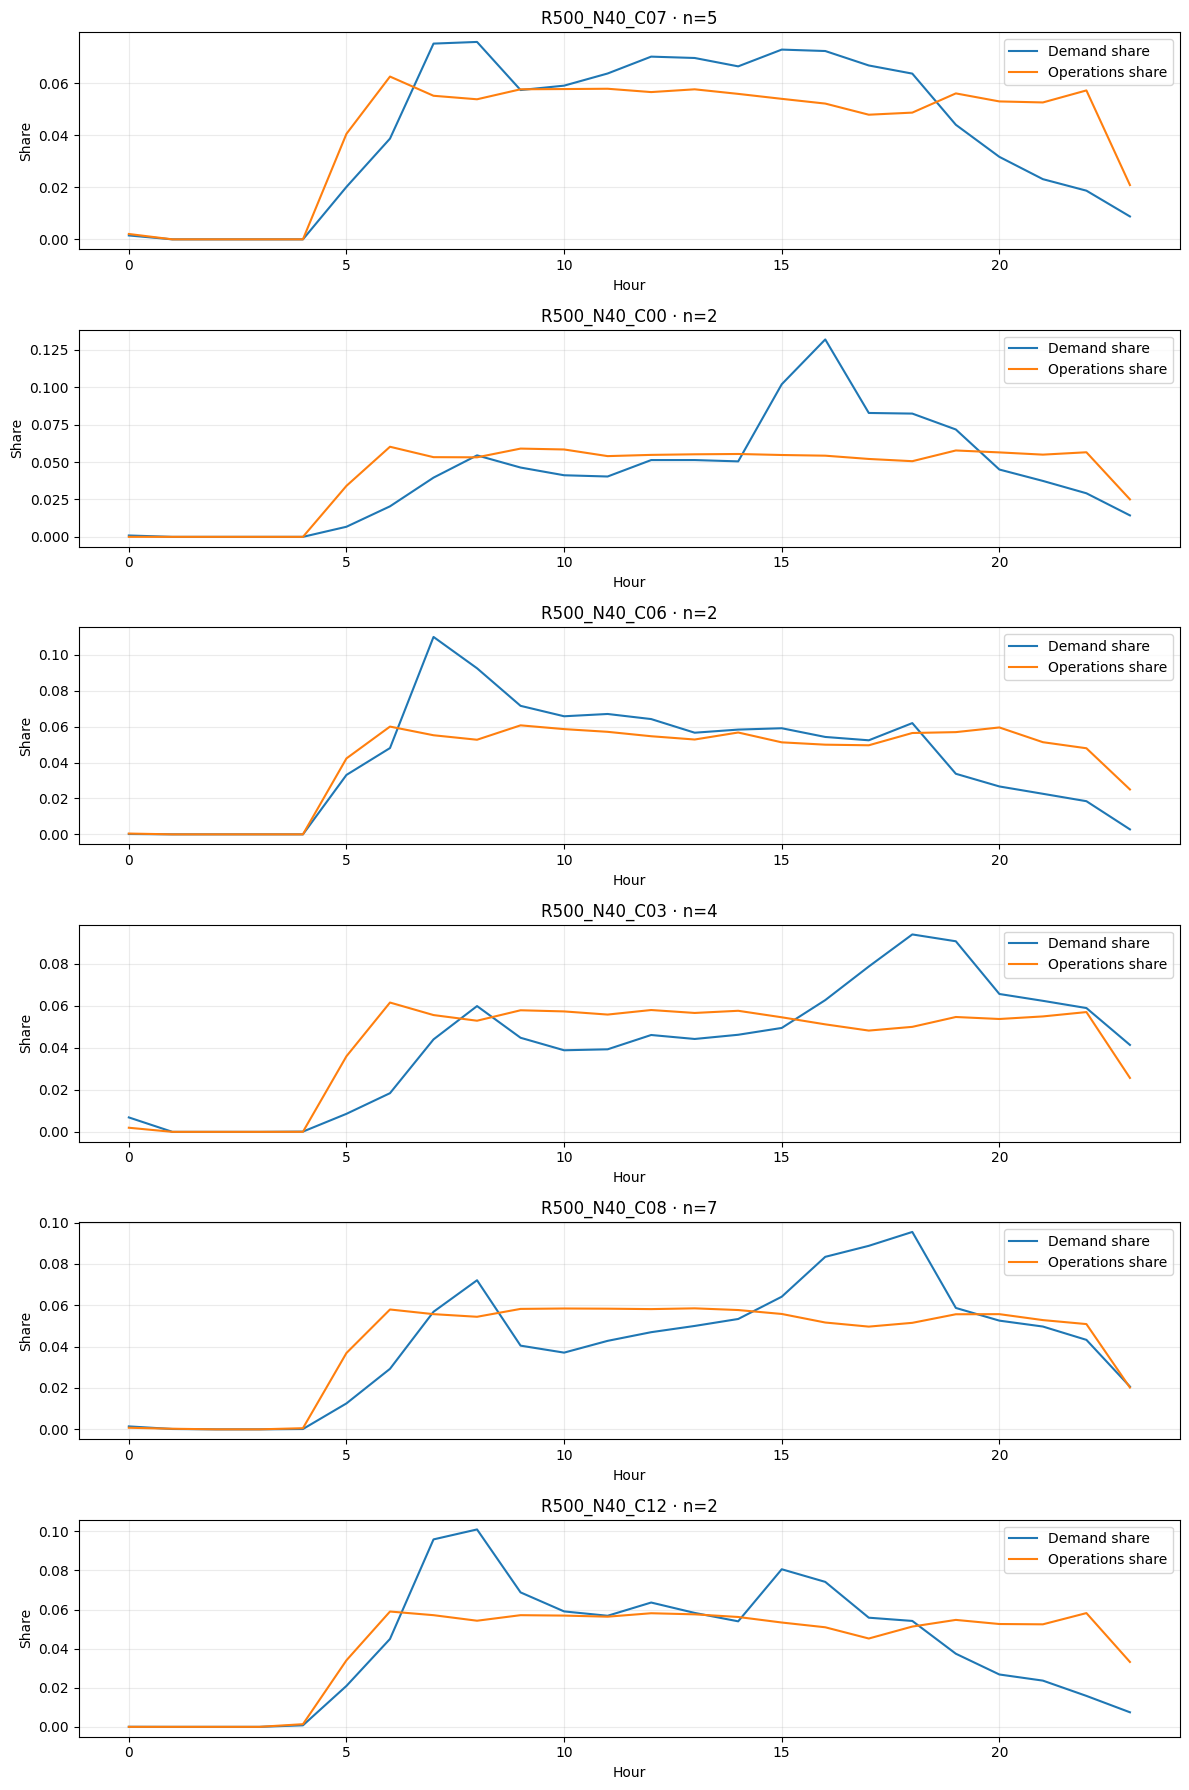

In [8]:
by_hour=month_data.groupby(['zone_id','hour']).agg(boardings=('passenger_count','sum'),operations=('operation_count','sum'),positive_demand_zero_ops=('passenger_positive_operation_zero', 'sum')).reset_index()
by_hour['demand_share']=by_hour.boardings/by_hour.groupby('zone_id').boardings.transform('sum').replace(0,np.nan)
by_hour['operation_share']=by_hour.operations/by_hour.groupby('zone_id').operations.transform('sum').replace(0,np.nan)
by_hour['relative_gap']=by_hour.demand_share-by_hour.operation_share
by_hour.to_csv(OUT/'08_hourly_zone_patterns.csv',index=False,encoding='utf-8-sig')
peak=by_hour.loc[by_hour.groupby('zone_id').relative_gap.idxmax(),['zone_id','hour','relative_gap']].rename(columns={'hour':'largest_relative_gap_hour','relative_gap':'largest_relative_gap'})
peak=zones[['zone_id','n_stop_groups','station_names']].merge(peak,on='zone_id').sort_values('largest_relative_gap',ascending=False)
peak.to_csv(OUT/'09_largest_relative_gap_hours.csv',index=False,encoding='utf-8-sig')
display(peak.head(15))
# 군집 크기가 큰 실제 공간 권역 상위 6개 패턴
big=zones[zones.n_stop_groups>=2].head(6).zone_id.tolist()
if big:
 fig,axs=plt.subplots(len(big),1,figsize=(12,3*len(big)),squeeze=False)
 for ax,z in zip(axs[:,0],big):
  d=by_hour[by_hour.zone_id==z]
  ax.plot(d.hour,d.demand_share,label='Demand share')
  ax.plot(d.hour,d.operation_share,label='Operations share')
  ax.set(title=f'{z} · n={int(zones.loc[zones.zone_id==z,"n_stop_groups"].iloc[0])}',xlabel='Hour',ylabel='Share');ax.legend();ax.grid(alpha=.25)
 plt.tight_layout();plt.savefig(OUT/'10_zone_hourly_profiles.png',dpi=160);plt.show()


## 6. 반경 민감도: 같은 정류장명들의 공동 권역 배정 일치율
거리 임계값이 바뀔 때 두 정류장군이 같은 공간 권역에 함께 들어가는지 비교합니다. **비교 대상은 각 시나리오 공통 후보**이며, 대표 좌표의 정확성 검증을 대신하지 않습니다.

In [9]:
from itertools import combinations
rows=[]
def colocated_pairs(df):
 return set(tuple(sorted([a,b])) for _,g in df.groupby('zone_id') for a,b in combinations(g.station_name.tolist(),2))
for pool in [20,40,60]:
 scen={r:group_candidates(pool,r) for r in [300,500,800]}
 for r1,r2 in [(300,500),(500,800),(300,800)]:
  a,b=colocated_pairs(scen[r1]),colocated_pairs(scen[r2]);union=a|b
  rows.append(dict(pool=pool,radius_a=r1,radius_b=r2,coassigned_pair_jaccard=(len(a&b)/len(union) if union else 1.0),pairs_a=len(a),pairs_b=len(b)))
sens=pd.DataFrame(rows);display(sens)
sens.to_csv(OUT/'11_radius_sensitivity.csv',index=False,encoding='utf-8-sig')


,pool,radius_a,radius_b,coassigned_pair_jaccard,pairs_a,pairs_b
0,20,300,500,0.285714,2,7
1,20,500,800,0.241379,7,29
2,20,300,800,0.068966,2,29
3,40,300,500,0.166667,7,42
4,40,500,800,0.106329,42,395
5,40,300,800,0.017722,7,395
6,60,300,500,0.148760,18,121
7,60,500,800,0.119212,121,1015
8,60,300,800,0.017734,18,1015


## 7. 지도 시각화 (Folium HTML)
지도는 위치가 검증된 정류장군만 표시하고, 불확실 37개를 임의 위치에 표시하지 않습니다. 대표좌표는 정류장군 표시용일 뿐 정확한 승차지점은 아닙니다.

In [10]:
import folium
if not base.empty:
 m=folium.Map(location=[base.representative_latitude.mean(),base.representative_longitude.mean()],zoom_start=12,tiles='CartoDB positron')
 for _,r in base.iterrows():
  label=f"{r.station_name} | {r.zone_id} | rank {r.rank_base} | repeat {r.top20_frequency}/4"
  folium.CircleMarker(location=[r.representative_latitude,r.representative_longitude],radius=5+1.4*r.top20_frequency,color=('#C46D18' if r.zone_type=='multi_stop_zone' else '#3864B3'),fill=True,fill_opacity=.75,tooltip=label).add_to(m)
 for _,r in zones[zones.n_stop_groups>=2].iterrows():
  folium.Marker([r.latitude,r.longitude],tooltip=f"{r.zone_id} / {r.n_stop_groups} stops",icon=folium.Icon(color='orange',icon='info-sign')).add_to(m)
 m.save(str(OUT/'12_candidate_zones_map.html'))
 display(m)


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 8. 감사표 + 다운로드
최종 권역은 미확정 상태입니다. 파일을 검토한 뒤 실제 도로망, 교차로, 하차 OD, 환승 편의성 및 접근성 검증을 추가해야 합니다.

In [11]:
audit=pd.DataFrame([
 {'check':'all_stops','value':len(scores)},
 {'check':'geocodable_stops','value':int(scores.spatial_valid.sum())},
 {'check':'non_geocodable_stops','value':int((~scores.spatial_valid).sum())},
 {'check':'median_demand_eligible','value':int(scores.eligible_median.sum())},
 {'check':'base_pool_size','value':len(base)},
 {'check':'base_multi_stop_zone_count','value':int((zones.n_stop_groups>=2).sum())},
 {'check':'base_singletons','value':int((zones.n_stop_groups==1).sum())},
 {'check':'monthly_observed_days','value':str(month_days.to_dict())}])
audit.to_csv(OUT/'13_audit_summary.csv',index=False,encoding='utf-8-sig')
display(audit)
zipname='Michuhol_IMOD_STEP5_Spatial_Zones_Results.zip'
with zipfile.ZipFile(zipname,'w',compression=zipfile.ZIP_DEFLATED) as z:
 for p in OUT.glob('*'):z.write(p,arcname=p.name)
print('생성 완료:',zipname);files.download(zipname)


,check,value
0,all_stops,286
1,geocodable_stops,249
2,non_geocodable_stops,37
3,median_demand_eligible,143
4,base_pool_size,40
5,base_multi_stop_zone_count,8
6,base_singletons,14
7,monthly_observed_days,"{'2026-04': 30, '2026-05': 31, '2026-06': 29}"


생성 완료: Michuhol_IMOD_STEP5_Spatial_Zones_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>